# Human Decision Making Under Uncertainty
* This is the final assignment for the *Applied Machine Learning* course.
* In this assignment, we analyze the [choices13k](https://github.com/jcpeterson/choices13k) dataset to study human decision-making under uncertainty.
* The dataset consists of 13,006 risky choice problems where participants had to choose between two gambles.
* Our main goal is to build a Machine Learning model that accurately predicts the `bRate` (the frequency with which participants selected Gamble B) based on the rewards and probabilities associated with each choice.

---

> Grigoris Alexandrou <br />
> t8220004@aueb.gr <br />
> Department of Management Science and Technology <br />
> Athens University of Economics and Business <br />

## Understanding the Data
* Let's begin with understanding the data that we have here.
* We will import the modules that we will be using later.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor


* We have two data sources (aka files).
* The first one is the `c13k_selections.csv`, that contains the aggregate data for **13,006 risky choice problems**. 
* It includes the features defining the two gambles (payoffs, probabilities, ambiguity, feedback, etc.) and the target variable **`bRate`** (the frequency with which participants selected Gamble B).
* The second one is `c13k_problems.json`, that contains the specific payoff amounts and associated probabilities for each problem, corresponding to the row indices in the CSV file.
* Let's read the first one.

In [2]:
df_selections = pd.read_csv('c13k_selections.csv')
df_selections

,Problem,Feedback,n,Block,Ha,pHa,La,Hb,pHb,Lb,LotShapeB,LotNumB,Amb,Corr,bRate,bRate_std
0,1,True,15,2,26,0.95,-1,23,0.05,21,0,1,False,0,0.626667,0.384460
1,2,True,15,4,14,0.60,-18,8,0.25,-5,0,1,True,-1,0.493333,0.413118
2,3,True,17,4,2,0.50,0,1,1.00,1,0,1,False,0,0.611765,0.432843
3,4,True,18,3,37,0.05,8,87,0.25,-31,1,2,False,0,0.222222,0.387383
4,5,False,15,1,26,1.00,26,45,0.75,-36,2,5,False,0,0.586667,0.450185
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14563,13002,True,15,3,30,1.00,30,42,0.80,0,0,1,True,0,0.367619,0.302731
14564,13003,True,15,5,70,0.50,-42,18,0.80,7,0,1,False,0,0.760000,0.364104
14565,13004,True,15,5,8,0.40,-17,31,0.40,-34,1,6,False,0,0.666667,0.367747
14566,13005,True,15,2,89,0.50,-49,45,0.50,-12,0,1,False,0,0.386667,0.381476


### Dataset Description & Feature Analysis

Based on the dataset [documentation](https://github.com/jcpeterson/choices13k/blob/main/README.md), we can categorize the columns into the following groups:

#### 1. Target Variable (Prediction Goal)
* **`bRate`**: The frequency with which participants selected **Gamble B**. This is a continuous value (float) ranging from 0 to 1. Our objective is to predict this value.

#### 2. Gamble A Features (Safe/Simple Option)
* **`Ha`**: The high payoff (reward) for Gamble A.
* **`pHa`**: The probability of receiving the high payoff (`Ha`).
* **`La`**: The low payoff for Gamble A (received with probability $1 - pHa$).

#### 3. Gamble B Features (Risky/Complex Option)
* **`Hb`**: The high payoff in Gamble B's lottery.
* **`pHb`**: The probability of triggering the lottery in Gamble B.
* **`Lb`**: The fixed outcome in Gamble B (if the lottery is not triggered).
* **`LotShapeB`**: The shape of the risk distribution (Symmetric, Skewed, etc.).
* **`LotNumB`**: The number of possible outcomes in the lottery.
* **`Amb` (Ambiguity)**: Binary flag. `True` if probabilities are hidden (ambiguous), `False` if known.

#### 4. Experiment Context & Metadata
* **`feedback`**: Whether participants received feedback after their choice.
* **`Corr`**: Correlation between payoffs of Gamble A and B.
* **`Block`**: The trial block ID (related to the experiment phase).
* **`n`**: Number of subjects who played this specific problem.
* **`problem`**: Unique ID for the problem scenario.

### Missing Data
* Let's check if there are any missing values in the data.
* Based on the documentation, there won't be any missing values but we have to check.

In [3]:
df_selections.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14568 entries, 0 to 14567
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Problem    14568 non-null  int64  
 1   Feedback   14568 non-null  bool   
 2   n          14568 non-null  int64  
 3   Block      14568 non-null  int64  
 4   Ha         14568 non-null  int64  
 5   pHa        14568 non-null  float64
 6   La         14568 non-null  int64  
 7   Hb         14568 non-null  int64  
 8   pHb        14568 non-null  float64
 9   Lb         14568 non-null  int64  
 10  LotShapeB  14568 non-null  int64  
 11  LotNumB    14568 non-null  int64  
 12  Amb        14568 non-null  bool   
 13  Corr       14568 non-null  int64  
 14  bRate      14568 non-null  float64
 15  bRate_std  14568 non-null  float64
dtypes: bool(2), float64(4), int64(10)
memory usage: 1.6 MB


* As we can see there is not any `null` value.
* And all the `Dtype` are as stated in the documentation.

### Summary Statistics
* Now let's see some descriptive statistics of the table.

In [4]:
df_selections.describe()

,Problem,n,Block,Ha,pHa,La,Hb,pHb,Lb,LotShapeB,LotNumB,Corr,bRate,bRate_std
count,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000,14568.000000
mean,6163.333677,16.670717,3.099053,22.014072,0.747192,3.813152,35.583677,0.444946,-4.147721,0.733869,2.724533,0.000137,0.518563,0.325973
std,3733.123605,2.588231,1.379569,24.076396,0.351998,16.406765,27.659754,0.325977,18.270573,0.949367,2.313364,0.285096,0.221819,0.074918
min,1.000000,15.000000,1.000000,-10.000000,0.010000,-50.000000,-18.000000,0.010000,-50.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,2961.750000,16.000000,2.000000,5.000000,0.500000,-6.000000,15.000000,0.200000,-16.000000,0.000000,1.000000,0.000000,0.360000,0.287518
50%,5888.500000,16.000000,3.000000,18.000000,1.000000,5.000000,30.000000,0.400000,-3.000000,0.000000,1.000000,0.000000,0.528961,0.339983
75%,9364.250000,17.000000,4.000000,29.000000,1.000000,17.000000,52.000000,0.750000,9.000000,1.000000,4.000000,0.000000,0.687500,0.378594
max,13006.000000,33.000000,5.000000,118.000000,1.000000,30.000000,119.000000,1.000000,41.000000,3.000000,8.000000,1.000000,1.000000,0.489728


* Based on the `describe()` method we can observe the following:

1. **Target Variable (`bRate`)**
    * **Mean**: The mean of bRate is 0.518. Participants selected Gamble B approximatelly 52% of the time on average.
    * **Range**: The values of bRate are in [0, 1]. This makes sense because bRate is the frequency with which participants selected Gamble B.
    * **std**: The standard deviation is 0.22. Substantial variability indicates diverse decision patterns across problems.
    * **Distribution**: Appears roughly balanced, no strong systematic preference for either gamble.
      
2. **Payoff Characteristics**  
    * **Gamble A**:  
        * High payoffs (`Ha`): The Mean is 22.01 and the Range is [-10, 118].
        * Low payoffs (`La`): The Mean is 3.81 and the Range is [-50, 30].
        * *Note*: Negative values indicate potential losses.  
      
    * **Gamble B**:
        * High payoff: (`Hb`): The Mean is 35.58 and the Range is [-18, 119].
        * Low payoff: (`Lb`): The Mean is -4.14 and the Range is [-50, 41].
        * *Note*: Gamble B tends to have **higher upside** but more **downside risk**.  
  
3. **Probabilities**  
    * **`pHa`** (prob of high payoff in A): Mean 0.747, many are certain (pHa=1.0 at 50th-75th percentile).
    * **`pHb`** (prob of lottery in B): Mean 0.444, more spread out (0.20 at 25th percentile, 0.75 at 75th).
    * **Interpretation:** Gamble A is often "safer", while Gable B is "riskier".
  
4. **Feature Scaling Requirements**  
    * **Significant scale differences** exist across feature types:  
        * **Payoffs** (`Ha`, `La`, `Hb`, `Lb`): Range from -50 to 119.
        * **Probabilities** (`pHa`, `pHb`): Range from 0.01 to 1.0.
        * **Categorical** (`LotNumB`, `Block`): Small integer ranges (1-8, 1-5)  
      
    * **Implication:** We will need to apply standardization before training ML models.  
  
5. **Experimental Design**  
    * **Sample size** (`n`): Mean ~17 participants per problem (range 15-33).
    * **Block**: Uniformly distributed across 5 experimental blocks.
    * **Feedback**: Boolean flag (no summary stats shown, but approximately 50% have feedback based on design).
    * **Ambiguity**: Boolean flag (~50% of problems involve hidden probabilities).
      
6. **Initial Insights**  
    * The relatively balanced mean bRate (~0.52) suggests neither gamble dominates systematically.
    * High variability in payoffs and probabilities indicates a diverse set of decision problems.
    * The presence of negative payoffs (losses) enables study of loss aversion.
    * Different experimental conditions (feedback, ambiguity, blocks) allow analysis of learning and uncertainty effects.

### Feature Engineering from JSON Data

* While the CSV file contains summary descriptors of each gamble, the `c13k_problems.json` file provides the **complete outcome-probability distributions** for both Gamble A and Gamble B in each problem.

#### Why should we use the JSON file?
* The data in the json file allows us to create **richer statistical features** that capture risk, uncertainty, and behavioral cues like loss aversion.
* By including metrics such as variance and entropy, as well as comparisons between gambles, we get a more complete picture of each decision.
* These advanced features complement the standard CSV data to provide a comprehensive representation of the problem.

In [5]:
json_path = "c13k_problems.json"
with open(json_path, "r") as f:
    problems = json.load(f)

print(type(problems), len(problems))
print("Example keys:", list(problems.keys())[:3])
print("Example entry:", problems["0"])


<class 'dict'> 14568
Example keys: ['0', '1', '2']
Example entry: {'B': [[0.95, 21.0], [0.05, 23.0]], 'A': [[0.95, 26.0], [0.050000000000000044, -1.0]]}


#### The `lottery_features()` Function

* We define a function to extract **11 structural features** from each gamble's probability distribution.
  
##### Statistical Moments
* **`ev`** (Expected Value): $\mathbb{E}[X] = \sum p_i \cdot x_i$ - mean outcome.
* **`var`** (Variance): $\text{Var}[X] = \sum p_i \cdot (x_i - \mathbb{E}[X])^2$ - risk squared.
* **`std`** (Standard Deviation): $\sqrt{\text{Var}[X]}$ - risk in original units.

##### Range Features
* **`n_outcomes`**: Number of possible outcomes.
* **`min`**: Worst possible outcome (e.g., -50 = loss of 50).
* **`max`**: Best possible outcome (e.g., 100 = gain of 100).
* **`range`**: $\text{max} - \text{min}$ - total spread.

##### Entropy
* **`entropy`**: $H(p) = -\sum p_i \log(p_i)$ - measures distributional uncertainty.
    * Low entropy: Deterministic
    * High entropy: Uniform across many outcomes

##### Gain/Loss Probabilities (Behavioral Features)
* **`prob_gain`**: $P(X > 0)$ - chance of winning money.
* **`prob_loss`**: $P(X < 0)$ - chance of losing money.
* **`prob_zero`**: $P(X = 0)$ - chance of breaking even.  
  
* **Behavioral Rationale:** People exhibit **loss aversion** (Kahneman & Tversky, [1979](https://web.mit.edu/curhan/www/docs/Articles/15341_Readings/Behavioral_Decision_Theory/Kahneman_Tversky_1979_Prospect_theory.pdf)) - they weigh losses more heavily than equivalent gains. Separating gain/loss probabilities captures this asymmetry.

In [6]:
def lottery_features(px_pairs):
    """
    px_pairs: list of [p, x] pairs from JSON, e.g. [[0.95, 21.0], [0.05, 23.0]]
    Returns a dict of engineered structural features.
    """
    p = np.array([t[0] for t in px_pairs], dtype=float)
    x = np.array([t[1] for t in px_pairs], dtype=float)

    # Normalize probabilities for numerical stability
    p = np.clip(p, 0, 1)
    s = p.sum()
    if s <= 0:
        p = np.ones_like(p) / len(p)
    else:
        p = p / s

    ev = np.sum(p * x)
    var = np.sum(p * (x - ev) ** 2)
    std = np.sqrt(var)

    x_min = float(np.min(x))
    x_max = float(np.max(x))
    x_range = x_max - x_min

    eps = 1e-12
    entropy = float(-np.sum(p * np.log(p + eps)))

    prob_loss = float(np.sum(p[x < 0])) if np.any(x < 0) else 0.0
    prob_gain = float(np.sum(p[x > 0])) if np.any(x > 0) else 0.0
    prob_zero = float(np.sum(p[x == 0])) if np.any(x == 0) else 0.0

    return {
        "n_outcomes": int(len(x)),
        "ev": float(ev),
        "var": float(var),
        "std": float(std),
        "min": x_min,
        "max": x_max,
        "range": float(x_range),
        "entropy": entropy,
        "prob_loss": prob_loss,
        "prob_gain": prob_gain,
        "prob_zero": prob_zero,
    }


In [7]:
json_rows = []
missing = 0

for i in range(len(df_selections)):
    key = str(i)
    if key not in problems:
        missing += 1
        continue

    entry = problems[key]

    feats_A = lottery_features(entry["A"])
    feats_B = lottery_features(entry["B"])

    row = {"row_index": i}
    row.update({f"A_{k}": v for k, v in feats_A.items()})
    row.update({f"B_{k}": v for k, v in feats_B.items()})

    # Differences (B - A)
    for k in feats_A.keys():
        row[f"diff_{k}"] = feats_B[k] - feats_A[k]

    json_rows.append(row)

print("Missing JSON entries:", missing)

df_json = pd.DataFrame(json_rows).set_index("row_index")
df_json.head()


Missing JSON entries: 0


,A_n_outcomes,A_ev,A_var,A_std,A_min,A_max,A_range,A_entropy,A_prob_loss,A_prob_gain,A_prob_zero,B_n_outcomes,B_ev,B_var,B_std,B_min,B_max,B_range,B_entropy,B_prob_loss,B_prob_gain,B_prob_zero,diff_n_outcomes,diff_ev,diff_var,diff_std,diff_min,diff_max,diff_range,diff_entropy,diff_prob_loss,diff_prob_gain,diff_prob_zero
row_index,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,2,24.65,34.6275,5.884514,-1.0,26.0,27.0,1.985152e-01,0.05,0.95,0.0,2,21.10,0.1900,0.435890,21.0,23.0,2.0,1.985152e-01,0.00,1.00,0.0,0,-3.55,-34.4375,-5.448624,22.0,-3.0,-25.0,-8.326673e-17,-0.05,0.05,0.0
1,2,1.20,245.7600,15.676734,-18.0,14.0,32.0,6.730117e-01,0.40,0.60,0.0,2,-1.75,31.6875,5.629165,-5.0,8.0,13.0,5.623351e-01,0.75,0.25,0.0,0,-2.95,-214.0725,-10.047569,13.0,-6.0,-19.0,-1.106765e-01,0.35,-0.35,0.0
2,2,1.00,1.0000,1.000000,0.0,2.0,2.0,6.931472e-01,0.00,0.50,0.5,1,1.00,0.0000,0.000000,1.0,1.0,0.0,-1.000089e-12,0.00,1.00,0.0,-1,0.00,-1.0000,-1.000000,1.0,-1.0,-2.0,-6.931472e-01,0.00,0.50,-0.5
3,2,9.45,39.9475,6.320403,8.0,37.0,29.0,1.985152e-01,0.00,1.00,0.0,3,-1.50,2610.8125,51.096110,-31.0,87.5,118.5,7.356219e-01,0.75,0.25,0.0,1,-10.95,2570.8650,44.775707,-39.0,50.5,89.5,5.371067e-01,0.75,-0.75,0.0
4,2,26.00,0.0000,0.000000,26.0,26.0,0.0,-1.000089e-12,0.00,1.00,0.0,6,24.75,1273.6875,35.688759,-36.0,71.0,107.0,1.537073e+00,0.25,0.75,0.0,4,-1.25,1273.6875,35.688759,-62.0,45.0,107.0,1.537073e+00,0.25,-0.25,0.0


#### Extraction Results
* We extracted **33 new features**.
* **11 for Gamble A** with the prefix `A_` and **11 for Gamble B** with the same structure.
* **11 difference features** with the prefix `diff_` which is B minus A for each metric.
* Human decision making is inherently comparative. People don't evaluate gambles in isolation, they compare.
* `diff_std`: Is B riskier than A? 
* `diff_ev`: Does B have higher expected value?
* `diff_prob_loss`: Does B have more potential for loss?
* Difference features capture these relative comparisons directly, often providing stronger predictive signals than absolute values alone.
* The print statement: Missing JSON entries is 0 and means that we have perfect alignment with the csv file.
* *Result*: We now have **49 total columns** (16 CSV + 33 JSON) ready for merging and modeling.

### Merging JSON Features with the CSV

* The JSON features are aligned by row index (each JSON entry corresponds to the same row in the CSV).
* We merge the engineered JSON features into the main dataframe and verify that no missing values were introduced.


In [8]:
df_all = df_selections.join(df_json, how="left")

print("Original shape:", df_selections.shape)
print("With JSON features:", df_all.shape)

missing_after_merge = df_all.isna().sum().sort_values(ascending=False)
missing_after_merge.head(10)


Original shape: (14568, 16)
With JSON features: (14568, 49)


Problem     0
Feedback    0
n           0
Block       0
Ha          0
pHa         0
La          0
Hb          0
pHb         0
Lb          0
dtype: int64

In [9]:
engineered_cols = df_json.columns.tolist()
num_missing_engineered = int(df_all[engineered_cols].isna().sum().sum())
print("Total missing values in engineered JSON features:", num_missing_engineered)

Total missing values in engineered JSON features: 0


## Problem Framing and Feature Selection

We now construct the supervised learning dataset using:
* `bRate` as the target variable (regression in [0, 1])
* All CSV features + engineered JSON features as predictors  
  
#### Feature Exclusions

**1. Problem Identifier**
The `Problem` identifier is excluded from the feature set to avoid using an ID as a predictive variable. However, we keep it separately as a **grouping variable** for:
- Train-test splitting (to prevent data leakage)
- Group-based cross-validation (to ensure same problem doesn't appear in both train and validation folds)

**2. bRate_std (Information Leakage)**
We exclude `bRate_std` from the feature set because:
- It is computed from the **same participant-level responses** as the target variable (`bRate`)
- In a real prediction scenario (e.g., predicting how people will respond to a **new** problem), we would not have this information available
- Including it would constitute **information leakage**, artificially inflating model performance

**Rationale for Exclusion:**
`bRate_std` measures the standard deviation of individual choice probabilities. While it provides valuable information about decision difficulty and consensus, it cannot be known *a priori* for new problems. Our goal is to predict human behavior from gamble characteristics alone, not from aggregate statistics of the responses themselves.


In [10]:
y = df_all["bRate"]

X = df_all.drop(columns=["bRate", "bRate_std", "Problem"])

groups = df_all["Problem"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of unique problems:", groups.nunique())


X shape: (14568, 46)
y shape: (14568,)
Number of unique problems: 13006


**X shape:** (14568, 46)
- 13 original CSV features (minus Problem, bRate, bRate_std)
- 33 engineered JSON features (lottery statistics, differences)
- Total: 46 predictive features

**y shape:** (14568,)
- Target: bRate (frequency of Gamble B selection)
- Range: [0, 1]
- Mean: ~0.52

**Unique Problems:** 13,006
- Some problems appear multiple times due to experimental conditions:
  - With vs. without feedback
  - Different block numbers (1-5)
- This is why 14,568 rows > 13,006 problems

**Group-Based Splitting is Essential:**
All observations from the same problem must stay together during train-test splitting and cross-validation to prevent data leakage.

### Train-Test Split
We use **`GroupShuffleSplit`** to split the data while respecting problem boundaries. This ensures:
1. **No leakage**: All observations from the same problem stay in either train OR test, never both
2. **Realistic evaluation**: The test set contains entirely unseen problems
3. **80/20 split**: Standard ratio for model development



In [11]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(X_train.shape, X_test.shape)

(11676, 46) (2892, 46)


#### Split Results
* The training set is 80% of our data, aka (11676, 46).
* The test set is 20% of our data, aka (2892, 46).
  
* The split maintains the group structure, allocating approximately 9300 problems to training and 2300 to testing with zero overlap between them.
* This ensures the test set remains completely untouched until the final evaluation, providing a strictly unbiased estimate of real-world performance.

### Cross-Validation Strategy
* To ensure that all observations corresponding to the same decision problem remain within the same fold, we use **group-based cross-validation** throughout the analysis.
* We use a 5-split **`GroupKFold`** strategy that partitions the approximately 9,300 unique problems - rather than individual observations - into five distinct folds.
* With each fold containing roughly 20% of the problems, the process involves training on four folds and validating on the remaining one.
* This cycle is repeated five times, ensuring that every fold serves as the validation set exactly once.  
  
#### Why GroupKFold instead of regular KFold?
* Regular KFold has the risk of data leakage by randomly splitting observations, which could place different conditions of the same problem into both training and validation sets.
* To prevent this, GroupKFold ensures that each unique problem is assigned to exactly one fold, effectively stopping the model from cheating by recognizing related data during validation.
* Consequently, we strictly use this GroupKFold strategy for all hyperparameter tuning and model selection to ensure the integrity of our results.

In [12]:
cv = GroupKFold(n_splits=5)

### Baseline Model
* As a baseline, we consider a simple predictor that always predicts the mean `bRate` observed in the training data. 
* This provides a reference point for evaluating the performance of more complex models.

In [13]:
y_pred_baseline = np.full_like(y_test, y_train.mean(), dtype=float)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = root_mean_squared_error(y_test, y_pred_baseline)
baseline_r2 = r2_score(y_test, y_pred_baseline)

baseline_mae, baseline_rmse, baseline_r2


(0.18530447441323722, 0.22323882347999963, -2.1273706766633538e-05)

#### Results
* This baseline model confirms that merely predicting the average choice rate of 52% for all problems is inadequate, yielding a Mean Absolute Error (MAE) of 0.185 or 18.5%.
* This means the model creates large errors, such as missing a true rate of 0.30 by over 20 points.
* Because human decision-making is complex and influenced by factors like payoffs and risk, our machine learning models must effectively learn these relationships to achieve an error rate significantly lower than 0.185.

### Machine Learning Models

#### Ridge Regression
* Ridge Regression is a linear model with **L2 regularization** to prevent overfitting by penalizing large coefficients. The regularization strength is controlled by the `alpha` parameter.  

##### Why Ridge?
1. Handles multicollinearity by shrinking correlated features
2. Provides a baseline for comparing with more complex models
3. Works well when relationships are approximately linear  
  
* We first evaluate Ridge with **default parameters** (alpha=1.0), then perform hyperparameter tuning to find the optimal regularization strength.


In [14]:
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

ridge_scores = cross_validate(
    ridge_pipeline,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

ridge_scores


{'fit_time': array([0.03803754, 0.02600241, 0.0263772 , 0.02488232, 0.02517915]),
 'score_time': array([0.00487685, 0.00434709, 0.00408626, 0.00413871, 0.0041914 ]),
 'test_neg_mean_absolute_error': array([-0.11629916, -0.1127671 , -0.11767602, -0.11616821, -0.11256261]),
 'test_neg_root_mean_squared_error': array([-0.14492233, -0.14088317, -0.14596425, -0.14370652, -0.14049785]),
 'test_r2': array([0.57037541, 0.59605613, 0.58297962, 0.57169662, 0.58684148])}

##### Baseline Ridge Results (alpha = 1.0):
* Cross-validated MAE: ~0.115 (mean across 5 folds)
* Cross-validated R2: ~0.58
  
* Ridge outperforms the dummy baseline, capturing approximately **58%** of variance.
* However, the moderate MAE suggests linear relationships alone are insufficient to model complex human decision-making patterns.


#### Random Forest Regressor
* Random Forest is an **ensemble method** that builds multiple decision trees on bootstrapped samples and averages their predictions.
* This reduces overfitting and improves generalization.  
  
##### Why Random Forest?
1. Captures non-linear relationships and feature interactions naturally
2. Robust to outliers and doesn't require feature scaling
3. Provides feature importance rankings
4. Less prone to overfitting than individual trees  
  
* We evaluate a baseline Random Forest with 200 trees, then perform hyperparameter tuning to optimize performance.

In [15]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_scores = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

rf_scores


{'fit_time': array([3.20097303, 3.15314531, 3.35877419, 3.33240986, 3.11312747]),
 'score_time': array([0.05035543, 0.04089761, 0.05187893, 0.05071878, 0.05047894]),
 'test_neg_mean_absolute_error': array([-0.08150145, -0.08168479, -0.08109702, -0.08151257, -0.07920515]),
 'test_neg_root_mean_squared_error': array([-0.10224185, -0.10198903, -0.10234426, -0.1040466 , -0.10116661]),
 'test_r2': array([0.78616639, 0.78830544, 0.79498234, 0.77548035, 0.78578408])}

##### Baseline Random Forest Results (n_estimators=200, default parameters):
* Cross-validated MAE: ~0.081 (using mean again)
* Cross-validated R2: ~0.79  
  
* Random Forest achieves a **30% improvement** over Ridge (MAE: 0.115 --> 0.081), confirming that decision-making involves significant non-linear patterns and interactions.
* The ensemble approach captures complexity that linear models miss.

#### Gradient Boosting Regressor
* Gradient Boosting builds trees **sequentially**, where each tree corrects the errors of previous trees.
* This iterative refinement often yields superior performance compared to Random Forest.  
  
##### Why Gradient Boosting?
1. Focuses on difficult-to-predict instances (high error cases)
2. Achieves high accuracy through sequential error correction
3. Highly flexible with extensive hyperparameter control
4. Often outperforms Random Forest in predictive competitions  
  
* We evaluate a baseline Gradient Boosting model with default parameters before tuning.

In [16]:
gbr_model = GradientBoostingRegressor(random_state=42)

gbr_scores = cross_validate(
    gbr_model,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
)

gbr_scores


{'fit_time': array([3.14058876, 3.1105454 , 3.09691739, 3.05682111, 3.11933303]),
 'score_time': array([0.00388145, 0.00470734, 0.00383472, 0.00380397, 0.00362182]),
 'test_neg_mean_absolute_error': array([-0.08647364, -0.08398635, -0.0863657 , -0.0851989 , -0.08300705]),
 'test_neg_root_mean_squared_error': array([-0.10945936, -0.10545209, -0.10906492, -0.10878657, -0.10555123]),
 'test_r2': array([0.75491069, 0.77368507, 0.76717241, 0.75455788, 0.7668132 ])}

##### Baseline Gradient Boosting Results (default parameters):
* Cross-validated MAE: ~0.085 (using mean again)
* Cross-validated R2: ~0.76  
  
* Gradient Boosting performs comparably to Random Forest with default settings.
* The sequential nature shows promise for improvement through careful hyperparameter tuning (learning rate, tree depth, number of estimators).

### Baseline vs ML Comparison
* Before hyperparameter tuning, we compare all models using cross-validated metrics.  
  
#### Observations so far:
1. **Ridge** (MAE: 0.115) establishes a linear baseline
2. **Random Forest** (MAE: 0.081) shows 30% improvement through non-linearity
3. **Gradient Boosting** (MAE: 0.085) performs similarly to Randmom Forest with defaults
4. All models outperform the dummy baseline (MAE: 0.185)  
  
* The tree-based ensembles clearly dominate, suggesting that human decision-making involves complex interactions between features that cannot be captured by linear models alone.
* Next, we perform hyperparameter tuning to optimize each model's performance.

In [17]:
def summarize_cv(scores):
    return {
        'MAE': -scores['test_neg_mean_absolute_error'].mean(),
        'RMSE': -scores['test_neg_root_mean_squared_error'].mean(),
        'R2': scores['test_r2'].mean()
    }

results = {
    'Baseline': {
        'MAE': baseline_mae,
        'RMSE': baseline_rmse,
        'R2': baseline_r2
    },
    'Ridge': summarize_cv(ridge_scores),
    'Random Forest': summarize_cv(rf_scores),
    'Gradient Boosting': summarize_cv(gbr_scores)
}

results


{'Baseline': {'MAE': 0.18530447441323722,
  'RMSE': 0.22323882347999963,
  'R2': -2.1273706766633538e-05},
 'Ridge': {'MAE': np.float64(0.11509462006865731),
  'RMSE': np.float64(0.14319482455334423),
  'R2': np.float64(0.5815898536835343)},
 'Random Forest': {'MAE': np.float64(0.08100019638566691),
  'RMSE': np.float64(0.10235767140496425),
  'R2': np.float64(0.7861437223707642)},
 'Gradient Boosting': {'MAE': np.float64(0.08500632894490161),
  'RMSE': np.float64(0.10766283562551551),
  'R2': np.float64(0.7634278506955336)}}

### Hyperparameter Tuning: Ridge Regression
* We use **GridSearchCV** to find the optimal `alpha` value, testing: {0.01, 0.1, 1.0, 10.0, 100.0}.
* Low alpha (e.g., 0.01): Minimal regularization, closer to standard linear regression.
* High alpha (e.g., 100): Strong regularization, heavily shrinks coefficients
* **Search Strategy**: Grid search with 5-fold cross-validation using GroupKFold to prevent leakage.

In [18]:
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

ridge_param_grid = {
    'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train, groups=groups_train)

ridge_grid.best_params_, -ridge_grid.best_score_


({'model__alpha': 0.01}, np.float64(0.11509236343933718))

#### Tuned Ridge Results
1. Best `alpha`: 0.01 (minimal regularization performs best)
2. Cross-validated MAE: 0.115  
  
* The hyperparameter tuning produced essentially no improvement, leaving the score unchanged at 0.1151.
* This suggests that regularization is not the issue, but rather that the linear model lacks the capacity to capture the complexities of human decision-making.
* The Ridge model has hit a clear performance ceiling at an MAE of roughly 0.115.

### Hyperparameter Tuning: Random Forest
* Random Forest has several key hyperparameters affecting performance:
    * **`n_estimators`**: Number of trees (more = better, but diminishing returns)
    * **`max_depth`**: Maximum tree depth (controls complexity vs. generalization)
    * **`min_samples_split`**: Minimum samples to split a node (prevents overfitting)
    * **`min_samples_leaf`**: Minimum samples in leaf nodes (smooths predictions)
* **Search Strategy:** RandomizedSearchCV with 20 iterations to efficiently explore the parameter space.
* *Note: This code cell might take a while to complete.*

In [19]:
rf_param_dist = {
    'n_estimators': [200, 400, 600],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=20,
    cv=cv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train, groups=groups_train)

rf_search.best_params_, -rf_search.best_score_


({'n_estimators': 600,
  'min_samples_split': 5,
  'min_samples_leaf': 2,
  'max_depth': 20},
 np.float64(0.0808117398016577))

#### Tuned Random Forest Results
1. Best parameters: *n_estimators*=600, *max_depth*=20, *min_samples_split*=5, *min_samples_leaf*=2
2. Cross-validated MAE: 0.0808  
  
* The tuning resulted in only small improvements, showing that the original Random Forest model was already effective.
* The best setup uses 600 deep trees to capture complex patterns and improve stability.
* It also applies moderate limits to the leaves to maintain a good balance between bias and variance.

### Hyperparameter Tuning: Gradient Boosting
* Gradient Boosting requires careful tuning as it's more sensitive to hyperparameters than Random Forest:
    * **`n_estimators`**: Number of boosting stages
    * **`learning_rate`**: Step size for each tree (trade-off with n_estimators)
    * **`max_depth`**: Tree depth (typically shallow for boosting, 2-5)
    * **`min_samples_leaf`**: Regularization through minimum leaf size
    * **`subsample`**: Fraction of samples for each tree (stochastic gradient boosting)
    * **`max_features`**: Fraction of features per tree (adds randomness)
* **Search Strategy:** RandomizedSearchCV with 40 iterations for comprehensive exploration.
* *Note: This might take a while to complete.*

In [20]:
gbr_param_dist = {
    "n_estimators": [300, 500, 800, 1200],
    "learning_rate": [0.01, 0.03, 0.05, 0.08],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [5, 10, 20, 40],
    "subsample": [0.6, 0.8, 1.0],
    "max_features": ["sqrt", 0.5, None],
}

gbr_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=gbr_param_dist,
    n_iter=40,                 
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    random_state=42,
)

gbr_search.fit(X_train, y_train, groups=groups_train)

gbr_search.best_params_, -gbr_search.best_score_


({'subsample': 0.6,
  'n_estimators': 800,
  'min_samples_leaf': 10,
  'max_features': None,
  'max_depth': 4,
  'learning_rate': 0.03},
 np.float64(0.07807900281098275))

#### Tuned Gradient Boosting Results
* Best parameters:
    * n_estimators=800, learning_rate=0.03 (many small steps)
    * max_depth=4 (shallow trees typical for boosting)
    * subsample=0.6, max_features=None
    * min_samples_leaf=10 (regularization)
* Cross-validated MAE: 0.0780
  
* Gradient Boosting benefited the most from tuning, improving the score by about 8.2% (from 0.085 to 0.0781).
* This is now our best-performing model.
* The optimal setup uses 800 shallow trees with a low learning rate to make small, gradual corrections, while using data subsampling to prevent overfitting.

### Neural Network Method: MLPRegressor
* MLPRegressor is a feed-forward neural network.  
  
#### Why Neural Networks?
1. Universal function approximators: can learn any continuous function
2. Automatically discover feature interactions through hidden layers
3. Can capture highly non-linear patterns  
  
#### Considerations
1. **Hidden layers**: Network depth and width
2. **Activation function**: Non-linearity (ReLU, tanh)
3. **Regularization (alpha)**: L2 penalty to prevent overfitting
4. **Learning rate**: Optimization step size  
  
* **Important:** Neural networks are sensitive to feature scales, so we use `StandardScaler` in a pipeline.
* **Search Strategy:** RandomizedSearchCV with 25 iterations to find optimal architecture and hyperparameters.

In [21]:
mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(
        random_state=42,
        max_iter=2000,
        early_stopping=True,
        n_iter_no_change=20
    ))
])

mlp_param_dist = {
    'model__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'model__alpha': [1e-5, 1e-4, 1e-3, 1e-2],
    'model__learning_rate_init': [1e-4, 5e-4, 1e-3, 5e-3],
    'model__activation': ['relu', 'tanh']
}

mlp_search = RandomizedSearchCV(
    mlp_pipeline,
    param_distributions=mlp_param_dist,
    n_iter=25,
    cv=cv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

mlp_search.fit(X_train, y_train, groups=groups_train)

mlp_search.best_params_, -mlp_search.best_score_


({'model__learning_rate_init': 0.005,
  'model__hidden_layer_sizes': (64, 32),
  'model__alpha': 0.01,
  'model__activation': 'relu'},
 np.float64(0.0820709690608475))

#### Tuned Neural Network Results
* Best architecture: (64, 32) - two hidden layers with 64 and 32 neurons
* Best hyperparameters: alpha=0.01, learning_rate=0.005, activation='relu'
* Cross-validated MAE: 0.0820
  
* The MLP performs well, ranking between the Random Forest and Gradient Boosting models.
* A simple two-layer network is sufficient to match the tree-based methods, using early stopping to prevent overfitting.
* Although it isn't the best model - since tree methods often handle tabular data better, especially with smaller datasets - it confirms that non-linear methods significantly outperform linear baselines.

### Final Test-Set Evaluation (All Approaches)
* After identifying the optimal hyperparameters through cross-validation, we proceed to the final evaluation stage.
* We fit each tuned model on the entire training dataset and then evaluate it exactly once on the separate, held-out test set.
* This strict process provides an unbiased estimate of how the models will perform in real-world scenarios.
* To measure success, we report the Mean Absolute Error (MAE) as our primary metric, while also examining the Root Mean Squared Error (RMSE) to account for large errors and the R2 score to understand how much of the variance is explained.
* Crucially, because the test set was completely hidden during the entire training and tuning process, these results serve as genuine proof of the models' ability to generalize to new, unseen data.

In [22]:
def eval_on_test(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    }

models_best = {
    'Ridge (tuned)': ridge_grid.best_estimator_,
    'Random Forest (tuned)': rf_search.best_estimator_,
    'Gradient Boosting (tuned)': gbr_search.best_estimator_,
    'Neural Network MLP (tuned)': mlp_search.best_estimator_
}

test_results = {name: eval_on_test(model, X_train, y_train, X_test, y_test)
                for name, model in models_best.items()}

test_results_df = pd.DataFrame(test_results).T.sort_values('MAE')
test_results_df

,MAE,RMSE,R2
Gradient Boosting (tuned),0.075435,0.094945,0.819109
Random Forest (tuned),0.078259,0.099244,0.802360
Neural Network MLP (tuned),0.079870,0.100783,0.796183
Ridge (tuned),0.116444,0.145027,0.577949


#### Final Results Summary
##### Best Model: Gradient Boosting Regressor
* MAE: 0.075435
* RMSE: 0.094945
* R2: 0.819109  
  
##### Model Rankings
1. Gradient Boosting: 0.075435
2. Random Forest: 0.078259
3. Neural Network MLP: 0.079870
4. Ridge Regression: 0.116444  
  
* Tree-based ensembles dominate the results, with Gradient Boosting being the winner.
* This success proves that human decision-making is non-linear and relies on complex feature interactions rather than simple maximization strategies.
* Next up we have to document which features are important and how, for the best approach (aka Gradient Boosting).

## Feature Importance
* After identifying **Gradient Boosting** as our best-performing model, we now will investigate which features drive the predictions and how they influence decision-making.
* Feature importance in tree-based models measure how much each feature contributes to reducing prediction error across all decision trees.
* Features with higher importance have a stronger impact on the model's ability to predict human choices.
* Understanding feature importance is crucial because it allows us to validate behavioral theories by checking if key features align with established concepts like Prospect Theory and loss aversion.
* It also helps us interpret the model's internal logic by identifying which specific factors weigh most heavily when predicting the choice rate.
* Ultimately, this analysis provides deeper domain insights, revealing the fundamental drivers behind human decision-making under uncertainty.

In [23]:
best_gbr = gbr_search.best_estimator_
best_gbr.fit(X_train, y_train)
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_gbr.feature_importances_
}).sort_values(by='Importance', ascending=False)
print("Top 15 Most Important Features:")
print(feature_importance.head(15).to_string(index=False))
print(f"\nTotal features: {len(feature_importance)}")

Top 15 Most Important Features:
       Feature  Importance
       diff_ev    0.433615
diff_prob_gain    0.144101
      diff_max    0.073385
      diff_min    0.062182
diff_prob_loss    0.030134
           Amb    0.028326
         A_var    0.017254
         B_max    0.016056
         B_var    0.015962
           pHb    0.015524
         B_std    0.011945
  diff_entropy    0.011922
          A_ev    0.011678
            Ha    0.009950
         A_std    0.008408

Total features: 46


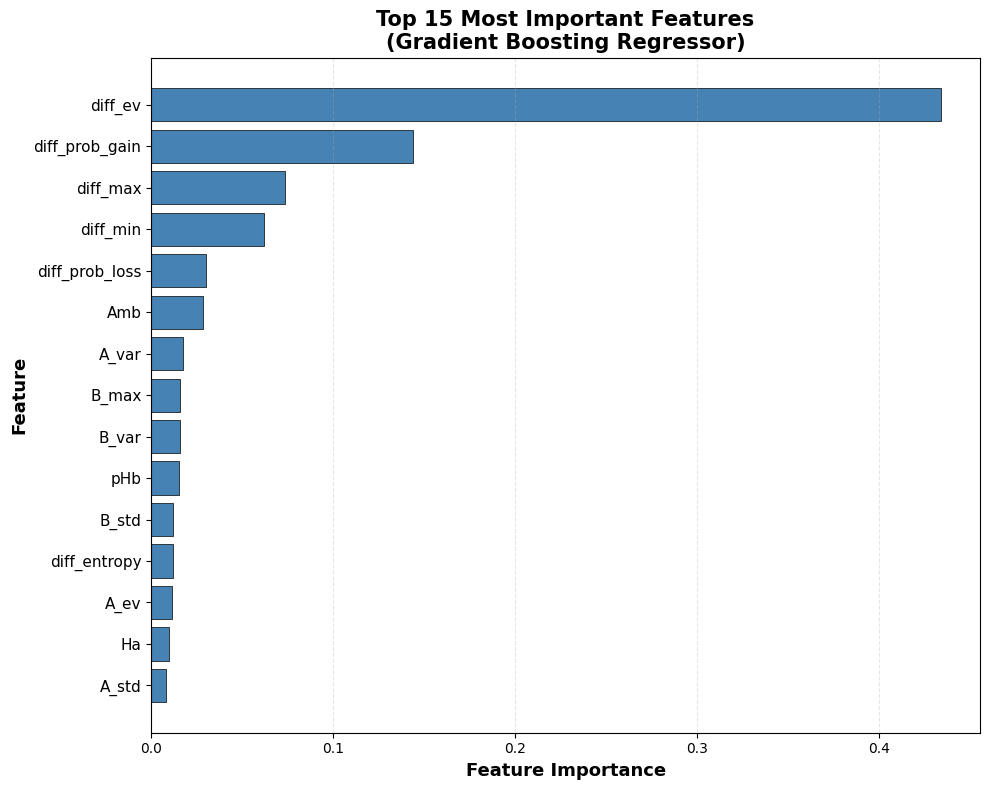

In [24]:
plt.figure(figsize=(10, 8))

top_15 = feature_importance.head(15)

plt.barh(range(len(top_15)), top_15['Importance'], color='steelblue', edgecolor='black', linewidth=0.5)
plt.yticks(range(len(top_15)), top_15['Feature'], fontsize=11)
plt.xlabel('Feature Importance', fontsize=13, fontweight='bold')
plt.ylabel('Feature', fontsize=13, fontweight='bold')
plt.title('Top 15 Most Important Features\n(Gradient Boosting Regressor)', fontsize=15, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

### Findings
* The feature importance analysis reveals the factors that drive human decision-making predictions in our Gradient Boosting model.

#### Top 5 Most Important Features
1. **`diff_ev`** (Importance: 0.434): **Difference in Expected Values (B − A)**.
    * **Interpretation**: By far the most critical factor (43% of total importance). The model primarily asks: "Does Gamble B have a higher expected value than Gamble A?".
    * **Behavioral Insight**: Validates rational choice theory - people fundamentally consider which gamble offers better average outcomes. However, with only 43% importance, this shows humans are NOT purely rational maximizers.
  
2. **`diff_prob_gain`** (Importance: 0.144): **Difference in Probability of Gains (B − A)**.
    * **Interpretation**: The relative chance of winning money between gambles matters significantly.
    * **Behavioral Insight**: People compare "Which gamble gives me a better chance of winning?" This shows probability weighting - people don't just look at expected values, but also at the likelihood of positive outcomes.
  
3. **`diff_max`** (Importance: 0.073): **Difference in Maximum Outcomes (B − A)**.
    * **Interpretation**: The potential best-case scenario influences decisions.
    * **Behavioral Insight**: Supports optimism bias or upside potential sensitivity - people are attracted to gambles with higher maximum payoffs, even if the expected value doesn't fully justify it.
  
4. **`diff_min`** (Importance: 0.062) - **Difference in Minimum Outcomes (B − A)**
   - **Interpretation**: The worst-case scenario matters.
   - **Behavioral Insight**: Validates loss aversion and downside risk concern - people consider "What's the worst that can happen?" when comparing gambles.
  
5. **`diff_prob_loss`** (Importance: 0.030) - **Difference in Probability of Losses (B − A)**
   - **Interpretation**: The relative chance of losing money matters, though less than probability of gains.
   - **Behavioral Insight**: Confirms loss aversion ([Prospect Theory](https://web.mit.edu/curhan/www/docs/Articles/15341_Readings/Behavioral_Decision_Theory/Kahneman_Tversky_1979_Prospect_theory.pdf)) - people care about which gamble has more downside risk, though interestingly, the probability of *gains* matters more than the probability of *losses*.

#### Other Notable Features

6. **`Amb`** (Importance: 0.028) - **Ambiguity**
   - **Interpretation**: Whether probabilities were disclosed affects choices modestly.
   - **Behavioral Insight**: Confirms ambiguity aversion - people behave differently when uncertainty is involved.

7. **`A_var`** (Importance: 0.017) - **Variance of Gamble A**
   - **Interpretation**: The riskiness of the reference gamble matters.
   - **Behavioral Insight**: Risk characteristics of both gambles are considered, not just their comparison.

8. **`B_max`** (Importance: 0.017) - **Maximum Outcome in Gamble B**
   - **Interpretation**: The absolute best outcome in B influences choices.
   - **Behavioral Insight**: Shows people don't purely think relatively - absolute magnitudes matter too.

#### Insights from Feature Importance
1. Difference Features Dominate (67% of total importance)
    * `diff_ev` (43%), `diff_prob_gain` (14%), `diff_max` (7%), `diff_min` (6%), `diff_prob_loss` (3%), `diff_entropy` (1%)
    * **Insight**: Decision-making is inherently comparative. People don't evaluate gambles in isolation - they ask "Which is better?" across multiple dimensions.
  
2. Expected Value is King, But Not Dictator (43%)
    * `diff_ev` alone accounts for 43% of importance.
    * **Insight**: While expected value is the single most important factor, the remaining 57% comes from other features. This confirms humans use bounded rationality - they consider EV but also weigh risk, probabilities, and extremes.
  
3. Extremes Matter (Max & Min)
    * `diff_max` (7%) and `diff_min` (6%) together contribute 13%
    * **Insight**: People don't just think about averages - they consider best-case and worst-case scenarios. This is consistent with minimax and maximax heuristics in decision theory (Brandstätter et al., [2006](https://pure.mpg.de/rest/items/item_2100873_12/component/file_2100872/content)).
  
4. Ambiguity Has Modest Impact
    * `Amb` (3%)
    * **Insight**: While ambiguity aversion exists (Ellsberg, [1961](https://sites.socsci.uci.edu/~bskyrms/bio/readings/ellsberg.pdf)), it's a secondary factor compared to the gambles' objective properties.


## Best Mean Absolute Error 
### MAE: 7.5435%